In [32]:
from skyfield.api import load, wgs84, Topos
import numpy as np
from datetime import datetime, timedelta
import pytz
from tqdm import tqdm
from matplotlib import pyplot as plt
from scipy.optimize import minimize

In [34]:
from sys import platform
if platform == "linux" or platform == "linux2":
    path = '/home/jidazhang/Desktop/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
elif platform == "win32":
    path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'
else:
    path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'

satellites = load.tle_file(path)
lat, lon = +40.11389690596162, -88.22484814695467
lnb = wgs84.latlon(lat, lon)
ts = load.timescale()
start_time = datetime(2023, 10, 31, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

In [35]:
fs = 1e3
t = ts.utc(start_time)
duration = stop_time-start_time
n_list = np.arange(0, fs*duration.total_seconds(), 1).astype(int)

elevation, azimuth = np.empty(len(n_list)), np.empty(len(n_list))

for n in tqdm(n_list):
    dist = (satellites[0]-lnb).at(t)
    el, az, distance = dist.altaz()
    elevation[n], azimuth[n] = el.degrees, az.degrees
    # increment t which is ts.utc by 1000/fs milliseconds
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs))

  0%|          | 0/60000 [00:00<?, ?it/s]

100%|██████████| 60000/60000 [00:41<00:00, 1458.68it/s]


In [36]:
# Function to calculate the difference between observed and calculated azimuth and altitude
def difference(params, satellite, gt_location, ts):
    observer_location = Topos(params[0], params[1])
    topocentric = (satellite - observer_location).at(ts)
    alt, az, _ = topocentric.altaz()
    observed_altitude, observed_azimuth = alt.degrees, az.degrees

    topocentric = (satellite -gt_location).at(ts)
    alt, az, _ = topocentric.altaz()
    return np.sqrt((observed_altitude - alt.degrees)**2 + (observed_azimuth - az.degrees)**2)

# Initial guess for observer's latitude and longitude
initial_guess = [0, 0]
# Get the current time
ts = load.timescale()
current_time = ts.utc(start_time)

# Get the ground truth azimuth and altitude of the satellite from the observer's location
gt_location = Topos(latitude_degrees=lat, longitude_degrees=lon)
topocentric = (satellites[0] - gt_location).at(current_time)
observed_altitude, observed_azimuth, _ = topocentric.altaz()

# Optimize to find the observer's latitude and longitude
result = minimize(difference, initial_guess, args=(satellites[0], gt_location, current_time), method='L-BFGS-B')

# Extract the optimized latitude and longitude
optimized_latitude, optimized_longitude = result.x

print(f"Observer's Latitude: {optimized_latitude}, Observer's Longitude: {optimized_longitude}")

Observer's Latitude: 40.11389690649889, Observer's Longitude: -88.22484815077674


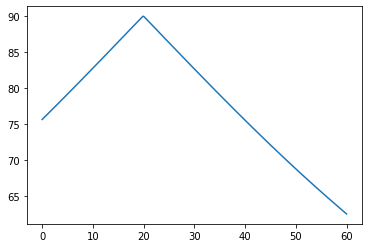

In [12]:
plt.plot(np.arange(0, 60, 0.1/100), elevation)
plt.show()